In [4]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


# Import & Setup

In [3]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add 'src' to Python path to import our modules
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from data_loader import load_all_data
from feature_eng import DataProcessor

# Visualization Settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print(" Setup Complete. Libraries Loaded.")

 Setup Complete. Libraries Loaded.


# Visualizing Physical Degradation (Voltage Curves)

Loading raw data...
Found 12 battery files. Loading...
 -> Processing: B0044.mat [OK]
 -> Processing: B0041.mat [OK]
 -> Processing: B0042.mat [OK]
 -> Processing: B0043.mat [OK]
 -> Processing: B0030.mat [OK]
 -> Processing: B0031.mat [OK]
 -> Processing: B0032.mat [OK]
 -> Processing: B0029.mat [OK]
 -> Processing: B0018.mat [OK]
 -> Processing: B0005.mat [OK]
 -> Processing: B0006.mat [OK]
 -> Processing: B0007.mat [OK]

Data Loading Complete!
Total Cycles: 1199
Unique Batteries: ['B0044' 'B0041' 'B0042' 'B0043' 'B0030' 'B0031' 'B0032' 'B0029' 'B0018'
 'B0005' 'B0006' 'B0007']
Ambient Temperatures: [22  4 43 24]


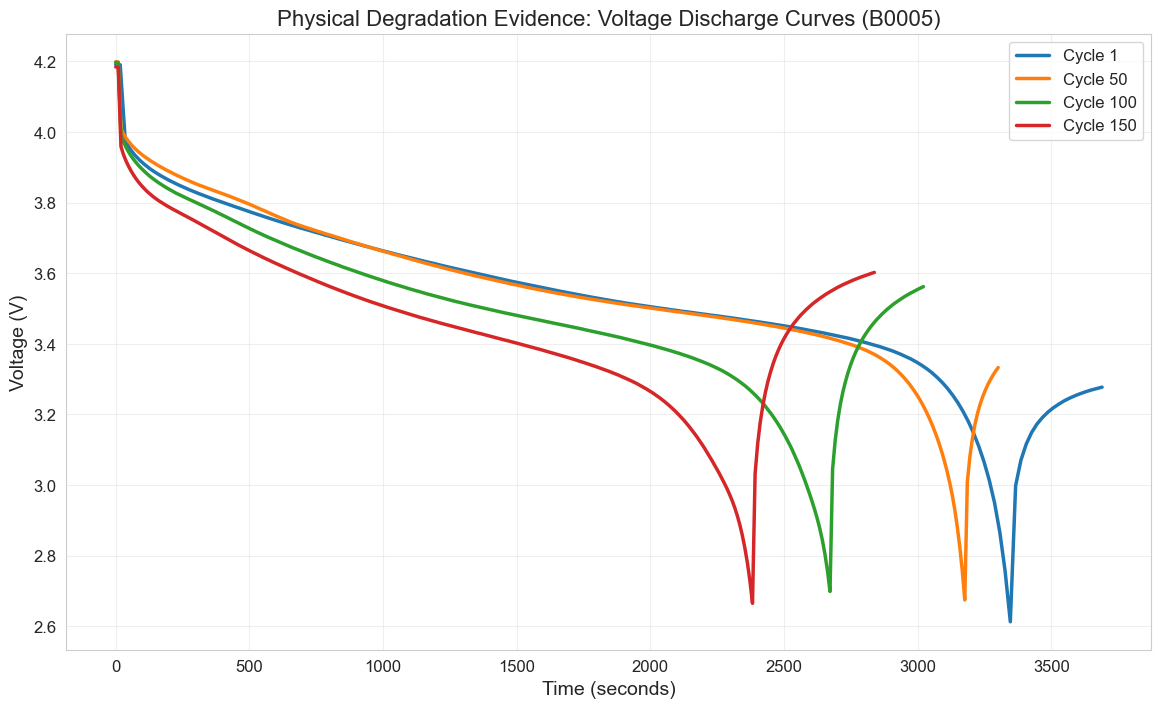

Observation: As the battery ages (Cycle 1 -> 150), the voltage drops significantly faster.


In [7]:
# Load Raw Data
print("Loading raw data...")
raw_df = load_all_data("../data/raw")

# Select a sample battery (B0005 - Standard Condition)
bat_id = 'B0005'
bat_data = raw_df[raw_df['battery_id'] == bat_id]

plt.figure(figsize=(14, 8))
colors = plt.cm.plasma(np.linspace(0, 1, 5))

# Plot voltage curves for specific cycles to show decay
selected_cycles = [1, 50, 100, 150]

for idx, cycle in enumerate(selected_cycles):
    cycle_data = bat_data[bat_data['cycle_count'] == cycle]
    
    if not cycle_data.empty:
        voltage = np.array(cycle_data.iloc[0]['voltage_measured'])
        time = np.array(cycle_data.iloc[0]['time_sec'])
        
        plt.plot(time, voltage, label=f'Cycle {cycle}', linewidth=2.5)

plt.title(f'Physical Degradation Evidence: Voltage Discharge Curves ({bat_id})', fontsize=16)
plt.xlabel('Time (seconds)', fontsize=14)
plt.ylabel('Voltage (V)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
print("Observation: As the battery ages (Cycle 1 -> 150), the voltage drops significantly faster.")

# Feature Correlation Matrix

Loaded processed features from disk.


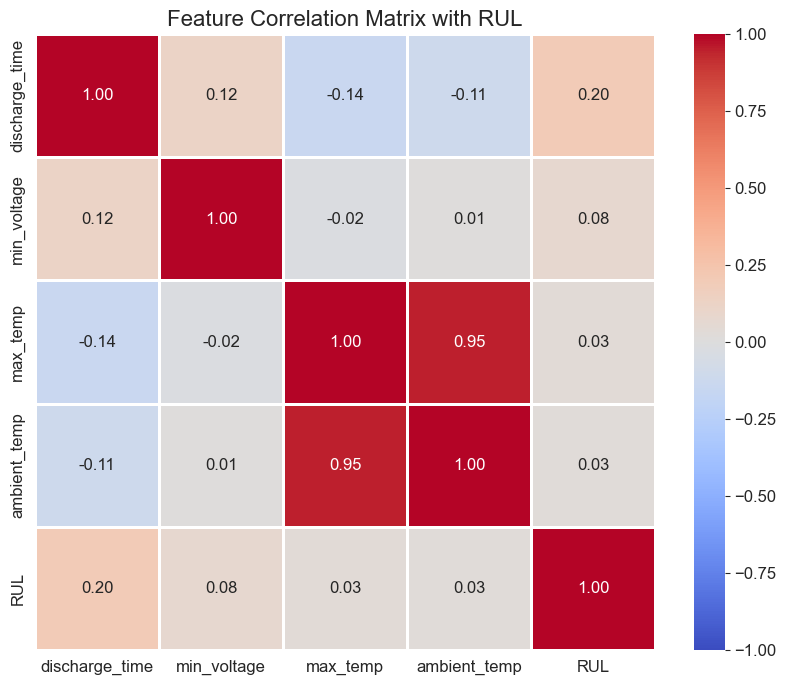

In [10]:
# Extract Features
processor = DataProcessor()
# Check if processed data exists to save time
if os.path.exists("../data/processed/final_features.csv"):
    feat_df = pd.read_csv("../data/processed/final_features.csv")
    print("Loaded processed features from disk.")
else:
    feat_df = processor.extract_features(raw_df)

# Calculate Correlation
cols_to_analyze = ['discharge_time', 'min_voltage', 'max_temp', 'ambient_temp', 'RUL']
corr_matrix = feat_df[cols_to_analyze].corr()

# Plot Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=1, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix with RUL', fontsize=16)
plt.show()